Accuracy: 1.0
              precision    recall  f1-score   support

       Alert       1.00      1.00      1.00         2
      Drowsy       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4

Prediction: Drowsy


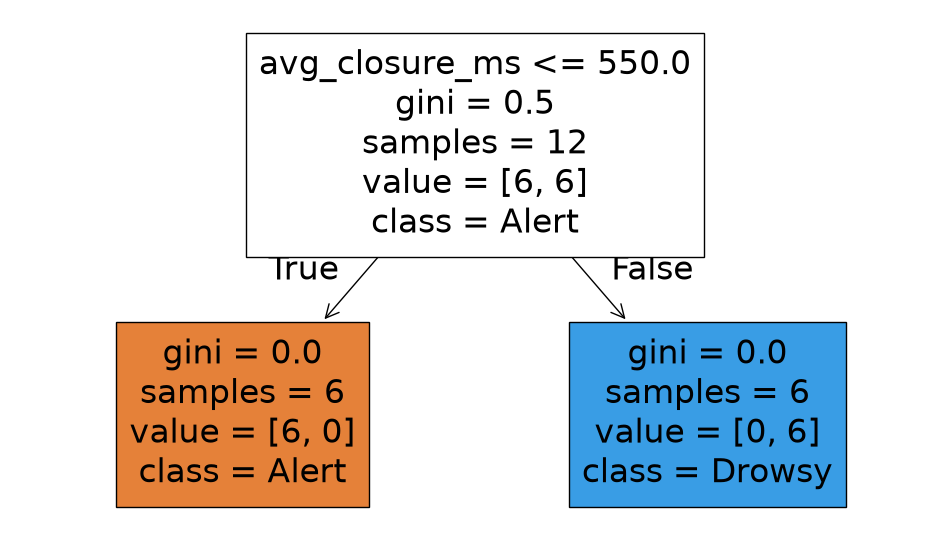

In [1]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# Create CSV file if it does not exist
data = pd.DataFrame({
    "closure_ratio": [0.2, 0.3, 0.7, 0.8, 0.4, 0.9, 0.6, 0.1,
                      0.75, 0.25, 0.85, 0.35, 0.65, 0.15, 0.95, 0.45],
    "avg_closure_ms": [200, 300, 700, 900, 400, 1000, 650, 150,
                       800, 250, 950, 350, 600, 180, 1100, 450],
    "blink_rate": [15, 18, 8, 6, 16, 5, 9, 20,
                   7, 17, 4, 19, 10, 22, 3, 14],
    "label": ["Alert", "Alert", "Drowsy", "Drowsy",
              "Alert", "Drowsy", "Drowsy", "Alert",
              "Drowsy", "Alert", "Drowsy", "Alert",
              "Drowsy", "Alert", "Drowsy", "Alert"]
})

data.to_csv("eye_closure.csv", index=False)

data = pd.read_csv("eye_closure.csv")

X = data[["closure_ratio", "avg_closure_ms", "blink_rate"]]
y = data["label"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=3,
    random_state=42
)
model.fit(X_train, y_train)


pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred, zero_division=0))

new_driver = pd.DataFrame(
    [[0.48, 850, 4]],
    columns=X.columns
)
print("Prediction:", model.predict(new_driver)[0])

plt.figure(figsize=(12, 7))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True
)
plt.show()
